In [1]:
!pip install lmfit


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
import matplotlib.pyplot as plt
import os
import scipy
from scipy.optimize import curve_fit
import numpy as np
import csv
from scipy.stats import linregress

from lmfit import Minimizer, Parameters, report_fit
import asteval
import uncertainties

In [3]:
file = "Calib.txt"
yellow_basic = "./Measurment Data/Yellow Lines/579nm2s100F Calibration.dat"
yellow_full = "./Measurment Data/Yellow Lines/579nm2s100F Without Pol 28A.dat"
yellow_pol90 = "./Measurment Data/Yellow Lines/579nm2s100F With Pol 90° 28A.dat"
yellow_pol180 = "./Measurment Data/Yellow Lines/579nm2s100F With Pol 180° 28A.dat"
DarkFrame1 = "./Measurment Data/Dark Frames/2s1000F.dat"
DarkFrame2 = "./Measurment Data/Dark Frames/282ms500F.dat"
green_basic = "./Measurment Data/Green Line/Calibration.dat"
green_full = "./Measurment Data/Green Line/Without Pol 27A.dat"
green_pol90 = "./Measurment Data/Green Line/With Pol 90° 27A.dat"
green_pol180 = "./Measurment Data/Green Line/With Pol 180° 27A.dat"

In [124]:
def read_mag_calib(filename):
    
    current = []
    fieldstrength = []
    
    with open(filename, newline="") as f:
        reader = csv.reader(f)
        next(reader) #skips header
        for row in reader:
            data = row[0].split("\t")
            current.append(int(data[0]))
            fieldstrength.append(int(data[1]))
    return current, fieldstrength

def get_mag_strength(current):
    current_calib, fieldstrength = read_mag_calib(file)
    for i in current_calib:
        if current_calib[i] == current:
            return fieldstrength[i]
        
def read_image(filepath):
    image = []
    with open(filepath, newline="") as f:
        reader = csv.reader(f)
        for row in reader:
            pixelrow = np.array(row[0].split("\t"))
            image.append(pixelrow.astype(int))
        return np.array(image)
    
def image_line(image, pixelstart, width):
    line = []
    for i in range(len(image)):
        line.append(image[i][pixelstart:pixelstart+width].sum())
    return np.array(line)

def lorentzian(x, amplitude, center, gamma):
    return amplitude * gamma**2 / ((x - center)**2 + gamma**2)

def fit_lorentizian(x_bounds, lineOut): #x_bounds im doppeltem array: [[start,ende],[start,ende]]
    x = np.linspace(0,len(lineOut),len(lineOut))
    
    fit_params_popt = []
    fit_params_pcov = []
    
    for param in x_bounds:
        #https://plotivy.app/techniques/lorentzian-fitting
        bounds = ([0, x.min(), 0.1], [np.inf, x.max(), np.inf])
        popt, pcov = curve_fit(lorentzian, x[param[0]:param[1]], lineOut[param[0]:param[1]], p0=[lineOut.max(), x[np.argmax(lineOut)], 5.0], bounds=bounds)
        
        fit_params_popt.append(popt)
        fit_params_pcov.append(pcov)
        
    return fit_params_popt, fit_params_pcov

def get_lorentzian(lineOut, fits_popt):
    x = np.linspace(0,len(lineOut),len(lineOut))
    
    lorentzians = []
    
    for popt in fits_popt:
        y_fit = lorentzian(x, *popt)
        lorentzians.append(y_fit)
        
    return lorentzians







def lorentzian_res(params, x, data = None, eps_data = None):
    """lmfit: calculates residuals for fitting of a lorentzian function"""
    back = params['back']
    amp = params['amp']
    gamma = params['gamma']
    x0 = params['x0']

    model = back + amp * gamma**2/ ((x - x0)**2 + gamma**2) 

    if data is None:                    # this way you can use the function also to plot the model function itself
        return model
    if eps_data is None:                # to make sure that the function can be used with or w/o uncertainties...
        return (data-model)
    return (data-model) / eps_data

def FP_lorentzian(params, x, data = None, eps_data = None):
    """lmfit: calculates residuals for fitting of 6 lorentzian peaks"""
    
    back = params['back']
    
    indiv = []
    
    for i in range(1,int((len(params)-1)/3)+1):
        a = "amp" + str(i)
        g = "gamma" + str(i)
        x0 = "x0" + str(i)
        indiv.append({"amp" : params[a], "gamma" : params[g], "xref" : params[x0]})
    
    model = back
    
    for i in indiv:        
        model += i["amp"] * i["gamma"]**2/ ((x - i["xref"])**2 + i["gamma"]**2)

    if data is None:                    # this way you can use the function also to plot the model function itself
        return model
    if eps_data is None:                # to make sure that the function can be used with or w/o uncertainties...
        return (data-model)
    return (data-model) / eps_data



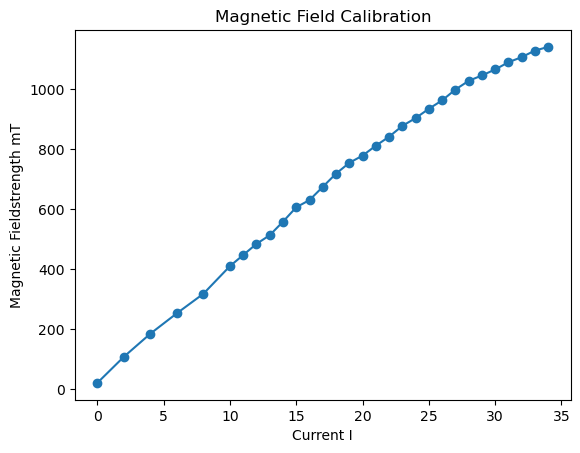

In [5]:
current, fieldstrength = read_mag_calib(file)

plt.plot(current, fieldstrength)  
plt.scatter(current, fieldstrength)  
plt.title("Magnetic Field Calibration")
plt.xlabel("Current I")
plt.ylabel("Magnetic Fieldstrength mT")
plt.show()

In [6]:
DarkFrame_yellow = read_image(DarkFrame1)

yellow_basic_image = read_image(yellow_basic) - DarkFrame_yellow/10
yellow_basic_image[yellow_basic_image < 100] = 0
yellow_basic_image = yellow_basic_image / yellow_basic_image.max()

yellow_full_image = read_image(yellow_full) - DarkFrame_yellow/10
yellow_full_image[yellow_full_image < 100] = 0
yellow_full_image = yellow_full_image / yellow_full_image.max()

yellow_pol90_image = read_image(yellow_pol90) - DarkFrame_yellow/10
yellow_pol90_image[yellow_pol90_image < 100] = 0
yellow_pol90_image = yellow_pol90_image / yellow_pol90_image.max()

yellow_pol180_image = read_image(yellow_pol180) - DarkFrame_yellow/10
yellow_pol180_image[yellow_pol180_image < 100] = 0
yellow_pol180_image = yellow_pol180_image / yellow_pol180_image.max()


#plt.imshow(yellow_basic_image)
##plt.savefig('yellow_basic_image.png')
#plt.show()
#
#plt.imshow(yellow_full_image)
##plt.savefig('yellow_full_image.png')
#plt.show()
#
#plt.imshow(yellow_pol90_image)
##plt.savefig('yellow_pol90_image.png')
#plt.show()
#
#plt.imshow(yellow_pol180_image)
##plt.savefig('yellow_pol180_image.png')
#plt.show()


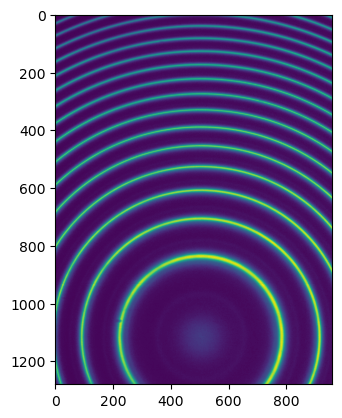

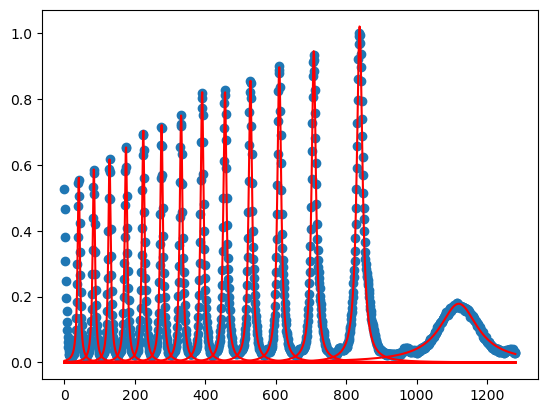

72.64585942120779


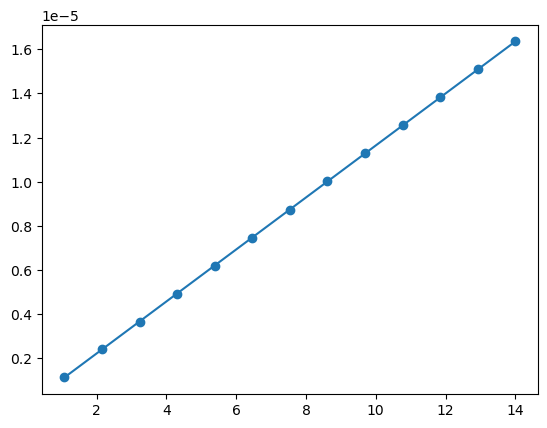

In [112]:
ImageData = read_image(green_basic) - read_image(DarkFrame2)
lineOut = image_line(ImageData, 500, 15)
lineOut_normal = lineOut / max(lineOut)

bounds = [[1000,1200],[790,845],[660,718],[590,640],[500,550],[440,480],[370,420],[310,350],[260,300],[210,250],[170,190],[110,140],[70,100],[20,50]]

fit_popt, fit_pcov = fit_lorentizian(bounds, lineOut_normal)
fits = get_lorentzian(lineOut_normal, fit_popt)

plt.imshow(ImageData)
#plt.savefig('Image-DarkFrame.png')
plt.show()


view = [1000,1200]
view = [0,len(lineOut)]

plt.scatter(np.linspace(0,len(lineOut),len(lineOut))[view[0]:view[1]],lineOut_normal[view[0]:view[1]])
for y_fit in fits:
    plt.plot(np.linspace(0,len(lineOut),len(lineOut))[view[0]:view[1]],y_fit[view[0]:view[1]],color='red')
plt.show()

radii = []

for i in range(len(fit_popt)):
    radii.append(fit_popt[i][1])
radii = np.array(radii)
radii -= radii[0]   #offset to center
radii *= 3.75e-6    #convert pixel to distance
radii *= -1         # kein physikalischer hintergrund nur damit es nicht negativ ist
radii *= radii

index = 1

x = np.linspace(0,len(radii),len(radii))
fit = linregress(x[index:], radii[index:])
y_fit = fit.slope * x + fit.intercept

residuals = radii - y_fit

slope = fit.slope
wavelength = 546.0735e-9 
d = 2.442e-3 

focal = np.sqrt((slope*d) / wavelength)*1000
print(focal)


plt.scatter(x[index:],radii[index:])
plt.plot(x[index:],y_fit[index:])
plt.show()

#plt.scatter(x[index:],residuals[index:])
#plt.show()


In [8]:
green_full_image = read_image(green_full) - read_image(DarkFrame2)/10
green_full_line = image_line(green_full_image, 500, 15)
green_full_line_normal = green_full_line / max(green_full_line)

green_pol90_image = read_image(green_pol90) - read_image(DarkFrame2)/10
green_pol90_line = image_line(green_pol90_image, 500, 15)
green_pol90_line_normal = green_pol90_line / max(green_pol90_line)

green_pol180_image = read_image(green_pol180) - read_image(DarkFrame2)/10
green_pol180_line = image_line(green_pol180_image, 500, 15)
green_pol180_line_normal = green_pol180_line / max(green_pol180_line)

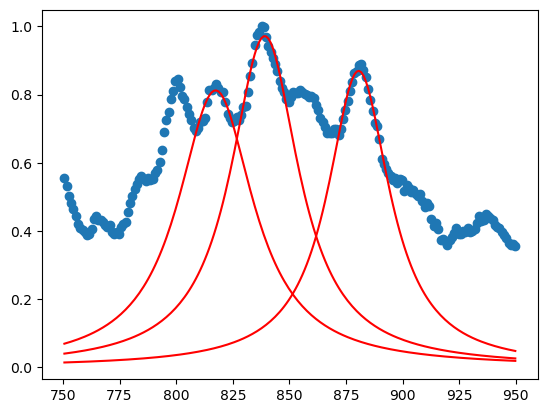

In [127]:
#plt.imshow(green_full_image)
#plt.show()
#,[799,805]
bounds = [[870,890],[830,850],[807,825]]

fit_popt, fit_pcov = fit_lorentizian(bounds, green_full_line_normal)
fits = get_lorentzian(green_full_line_normal, fit_popt)


view = [750,950]
#view = [0,len(green_full_line)]

plt.scatter(np.linspace(0,len(green_full_line),len(green_full_line))[view[0]:view[1]],(green_full_line_normal)[view[0]:view[1]])
for y_fit in fits:
    plt.plot(np.linspace(0,len(green_full_line),len(green_full_line))[view[0]:view[1]],y_fit[view[0]:view[1]],color='red')
plt.show()

In [128]:
lor6params = Parameters()
lor6params.add('back', value=16000, vary = True)
lor6params.add('amp1', value = 50000, vary = True)    # [vary=False] would fix this parameter to the given value
lor6params.add('gamma1', value = 0.00005, vary = True)
lor6params.add('x01', value = 0.00104, vary = True) 
lor6params.add('amp2', value = 50000, vary = True)    
lor6params.add('gamma2', value = 0.00005, vary = True)
lor6params.add('x02', value = 0.00104, vary = True) 
lor6params.add('amp3', value = 50000, vary = True)   
lor6params.add('gamma3', value = 0.00005, vary = True)
lor6params.add('x03', value = 0.00104, vary = True) 
lor6params.add('amp4', value = 50000, vary = True)   
lor6params.add('gamma4', value = 0.00005, vary = True)
lor6params.add('x04', value = 0.00104, vary = True) 
lor6params.add('amp5', value = 50000, vary = True)    
lor6params.add('gamma5', value = 0.00005, vary = True)
lor6params.add('x05', value = 0.00104, vary = True) 
lor6params.add('amp6', value = 50000, vary = True)    
lor6params.add('gamma6', value = 0.00005, vary = True)
lor6params.add('x06', value = 0.00104, vary = True) 
lor6params.add('amp7', value = 50000, vary = True)    
lor6params.add('gamma7', value = 0.00005, vary = True)
lor6params.add('x07', value = 0.00104, vary = True) 

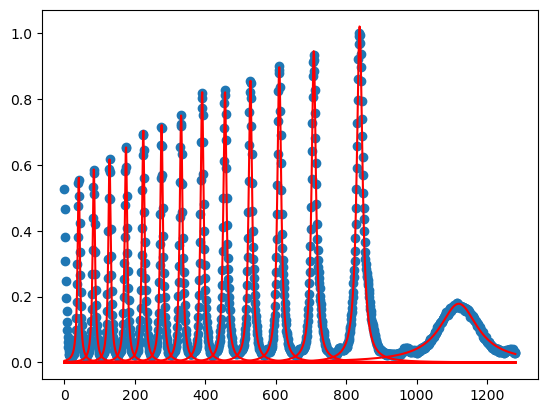

In [133]:
ImageData = read_image(green_basic) - read_image(DarkFrame2)
lineOut = image_line(ImageData, 500, 15)
lineOut_normal = lineOut / max(lineOut)

bounds = [[1000,1200],[790,845],[660,718],[590,640],[500,550],[440,480],[370,420],[310,350],[260,300],[210,250],[170,190],[110,140],[70,100],[20,50]]

fit_popt, fit_pcov = fit_lorentizian(bounds, lineOut_normal)
fits = get_lorentzian(lineOut_normal, fit_popt)

view = [1000,1200]
view = [0,len(lineOut)]

x = np.linspace(0,len(lineOut),len(lineOut))

plt.scatter(x[view[0]:view[1]],lineOut_normal[view[0]:view[1]])
for y_fit in fits:
    plt.plot(x[view[0]:view[1]],y_fit[view[0]:view[1]],color='red')
plt.show()



In [142]:
Kill_me = Minimizer(FP_lorentzian,lor6params,fcn_args=(x,lineOut))
resultlor = Kill_me.minimize()
finallor =  resultlor.residual

report_fit(resultlor)
resultlor.params.pretty_print()

print(resultlor)

#plt.plot(x,resultlor)
#plt.show()

[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 259
    # data points      = 1280
    # variables        = 22
    chi-square         = 7.5357e+13
    reduced chi-square = 5.9902e+10
    Akaike info crit   = 31786.2666
    Bayesian info crit = 31899.6682
[[Variables]]
    back:    185959.566 +/- 7074.77074 (3.80%) (init = 16000)
    amp1:    1.2284e+08 +/- 5.8502e+17 (476228325128.85%) (init = 50000)
    gamma1:  0.05878587 +/- 2.7048e+08 (460106604286.28%) (init = 5e-05)
    x01:    -2.37657691 +/- 1.1530e+10 (485158194698.38%) (init = 0.00104)
    amp2:    1.2284e+08 +/- 6.1434e+17 (500100429254.32%) (init = 50000)
    gamma2:  0.05878596 +/- 2.8753e+08 (489117859279.97%) (init = 5e-05)
    x02:    -2.37726751 +/- 1.2083e+10 (508272807577.89%) (init = 0.00104)
    amp3:    1.2284e+08 +/- 5.7521e+17 (468248407042.88%) (init = 50000)
    gamma3:  0.05878620 +/- 2.5801e+08 (438898585243.23%) (init = 5e-05)
    x03:    -2.37849451 +/- 1.0190e+10 (428416833086.

In [ ]:
def lorentzian_res(params, x, data = None, eps_data = None):
    """lmfit: calculates residuals for fitting of a lorentzian function"""
    back = params['back']
    amp = params['amp']
    gamma = params['gamma']
    x0 = params['x0']

    model = back + amp * gamma**2/ ((x - x0)**2 + gamma**2) 

    if data is None:                    # this way you can use the function also to plot the model function itself
        return model
    if eps_data is None:                # to make sure that the function can be used with or w/o uncertainties...
        return (data-model)
    return (data-model) / eps_data


minnerlor = Minimizer(lorentzian_res, lorparams, fcn_args=(energyaxis[300:480],((data_image6[:,380:420]-data_d2[:,380:420]/50).sum(axis=1))[300:480]))
resultlor = minnerlor.minimize()
finallor =  resultlor.residual